# KNN Homework - Week 8

Bank marketing dataset: predict whether a client subscribes to a term deposit (`y`) with K-Nearest Neighbors.

In [1]:
# (5pts) Step 1: Import necessary libraries and Load the dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

%matplotlib inline

df = pd.read_excel('bank_marketing.xlsx')

**Data repair.** The Excel file was saved with a Turkish locale, so Excel turned some decimal numbers into dates (e.g. `1.4` became 1 April) or removed the decimal point (e.g. `4.857` became `4857`). Four columns are affected, so we convert them back to their real numeric values before using them.

In [2]:
def fix_emp_var_rate(v):
    # date -> 'day.month' (1 Jan -> 1.1, 1 Apr -> 1.4)
    if isinstance(v, dt.datetime):
        return float(f'{v.day}.{v.month}')
    return float(v)

def fix_euribor3m(v):
    if isinstance(v, dt.datetime):          # date -> 'day.month' (e.g. 1 Mar -> 1.3)
        return float(f'{v.day}.{v.month}')
    if isinstance(v, str):
        return float(v)
    return v / 1000 if v >= 100 else float(v)   # 4857 -> 4.857 (values 1 and 5 are real integers)

def fix_nr_employed(v):
    # date -> 'year.month' (5228-01-01 -> 5228.1)
    if isinstance(v, dt.datetime):
        return float(f'{v.year}.{v.month}')
    return float(v)

df['emp.var.rate'] = df['emp.var.rate'].map(fix_emp_var_rate)
df['euribor3m'] = df['euribor3m'].map(fix_euribor3m)
df['nr.employed'] = df['nr.employed'].map(fix_nr_employed)
df['cons.price.idx'] = df['cons.price.idx'].map(lambda v: v / 1000 if v > 1000 else v)   # 93994 -> 93.994

df[['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']].describe().loc[['min', 'max']]

,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
min,-3.4,92.201,-50.8,0.634,4963.6
max,1.4,94.767,-26.9,5.045,5228.1


In [3]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
df.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [5]:
# (10 pts) Step 2: Preprocessing
# Convert categorical variables into numerical; one way to do is Label Encoding
df_encoded = df.copy()

le = LabelEncoder()
for col in df_encoded.select_dtypes(exclude='number').columns:
    df_encoded[col] = le.fit_transform(df_encoded[col])

df_encoded.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,3,1,0,0,0,0,1,6,1,...,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0,0
1,57,7,1,3,1,0,0,1,6,1,...,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0,0
2,37,7,1,3,0,2,0,1,6,1,...,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0,0
3,40,0,1,1,0,0,0,1,6,1,...,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0,0
4,56,7,1,3,0,0,2,1,6,1,...,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0,0


In [6]:
# (10 pts) Step 3: Define features (X) and target (y)
X = df_encoded.drop('y', axis=1)
y = df_encoded['y']

print(X.shape, y.shape)

(41188, 20) (41188,)


In [7]:
# (10 pts) Step 4: Scale the features (important for KNN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [8]:
# (5 pts) Step 5: Split into training and test sets (80&20)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(32950, 20) (8238, 20)


In [9]:
# (10 pts) Step 6: Find the optimal K using 5-fold cross-validation
k_values = range(1, 31)
error_rates = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)
    error_rates.append(1 - scores.mean())

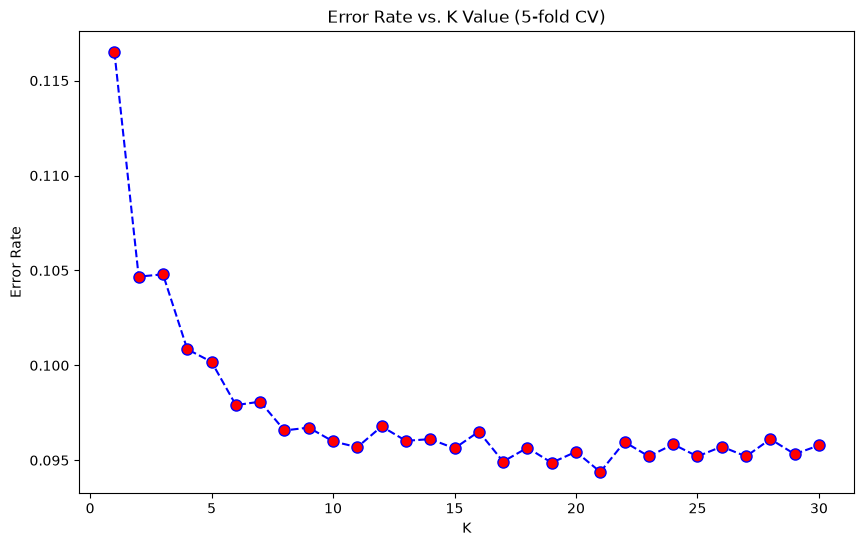

In [10]:
# (10 pts) Step 7: Plot the error rate for different K values
plt.figure(figsize=(10, 6))
plt.plot(k_values, error_rates, color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=8)
plt.title('Error Rate vs. K Value (5-fold CV)')
plt.xlabel('K')
plt.ylabel('Error Rate')
plt.show()

In [11]:
# (10 pts) Step 8: Find and print the optimal K (K with the minimum error rate)
optimal_k = list(k_values)[int(np.argmin(error_rates))]
print('Optimal K:', optimal_k)
print('Minimum error rate:', round(min(error_rates), 4))

Optimal K: 21
Minimum error rate: 0.0944


In [12]:
# (10 pts) Step 9: Train the final KNN model with the optimal K
knn_final = KNeighborsClassifier(n_neighbors=optimal_k)
knn_final.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",21
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [13]:
# (10 pts) Step 10: Make predictions
y_pred = knn_final.predict(X_test)
y_pred[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [14]:
# (10 pts) Step 11: Model evaluation
print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print()
print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred))
print()
print('Classification Report:')
print(classification_report(y_test, y_pred, target_names=['no', 'yes']))

Accuracy: 0.9031

Confusion Matrix:
[[7130  173]
 [ 625  310]]

Classification Report:
              precision    recall  f1-score   support

          no       0.92      0.98      0.95      7303
         yes       0.64      0.33      0.44       935

    accuracy                           0.90      8238
   macro avg       0.78      0.65      0.69      8238
weighted avg       0.89      0.90      0.89      8238



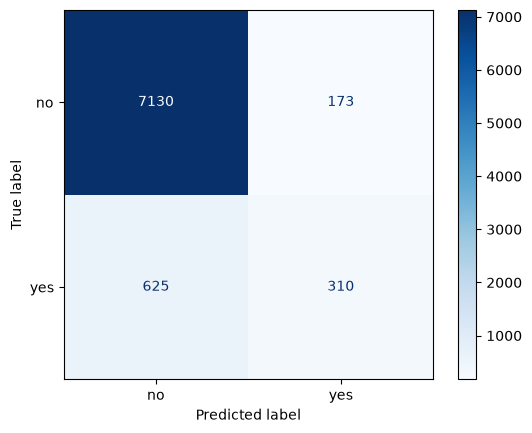

In [15]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['no', 'yes'], cmap='Blues')
plt.show()